## Read the data

In [1]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"
EXPERIMENT = 'core_identification'

In [2]:
DATA_PATH = f'D:/Google Drive/Work/ITMO/data/{EXPERIMENT}/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/retrained_models/"
RUNS = 20
TOTAL_SPLITS = 1

# Read models

In [3]:
MODELS_DESCRIPTIONS = {
    "viterbi_simple_with_pseudo_and_weights_7": {
        "path": "experiment_results/core_finding_models_viterbi_simple_with_pseudo/",
        "states": 7,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    # 'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": 7,
        "core_end_state": 8

    },
    "viterbi_with_pseudo_and_weights_7": {
        "path": "experiment_results/core_finding_models_viterbi_simple_with_pseudo/",
        "states": 35,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01',
                    # 'HLA-DPA1*01:03-DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [35],
        "core_end_state": [36],
        "need_to_delete": [37, 38]

    },
    "viterbi_multiple_7": {
        "path": "experiment_results/core_multiple_allele/",
        "states": 35,
        "params_string": "30-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-DRB1*01:01',
                    'HLA-DPA1*01:03/DPB1*04:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [35, 36],
        "core_end_state": [37, 38],
        "need_to_delete": [39, 40, 41, 42]

    },
    "viterbi_models_multiple_motifs": {
        "path": "experiment_results/core_identification/",
        "states": 7,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DQA1*05:01/DQB1*02:01', 

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [11,12, 13, 14, 15, 16, 17, 18, 19],
        "core_start_state": [7],
        "core_end_state": [8],
        "need_to_delete": [39, 40, 41, 42]

    },          "viterbi_models_multiple_motifs_35": {
        "path": "experiment_results/core_identification/",
        "states": 35,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DQA1*05:01/DQB1*02:01', 

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [11,12, 13, 14, 15, 16, 17, 18, 19],
        "core_start_state": [35, 36, 37],
        "core_end_state": [ 38,39, 40],
        "need_to_delete": [111]

    },
        "viterbi_models_multiple_motifs_35_12_18": {
        "path": "experiment_results/core_identification/",
        "states": 35,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DQA1*05:01/DQB1*02:01', 

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [35, 36, 37],
        "core_end_state": [ 38,39, 40],
        "need_to_delete": [111]

    },
         "viterbi_models_multiple_motifs_7_11_19": {
        "path": "experiment_results/core_identification/",
        "states": 7,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DQA1*05:01/DQB1*02:01', 

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [11, 12, 13, 14, 15, 16, 17, 18, 19],
        "core_start_state": [7],
        "core_end_state": [8],
        "need_to_delete": [111]

    },
                "viterbi_models_multiple_motifs_21_11_19": {
        "path": "experiment_results/core_identification/",
        "states": 21,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DQA1*05:01/DQB1*02:01', 

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [11, 12, 13, 14, 15, 16, 17, 18, 19],
        "core_start_state": [21,22, 23],
        "core_end_state": [24,25,26],
        "need_to_delete": [111]

    },
        "viterbi_models_multiple_motifs_21_12_18": {
        "path": "experiment_results/core_identification/",
        "states": 21,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 # 'HLA-DQA1*05:01/DQB1*02:01', 
              'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [21,22, 23],
        "core_end_state": [24,25,26],
        "need_to_delete": [111]

    },     
    "viterbi_models_multiple_motifs_21_13_17": {
        "path": "experiment_results/core_identification/",
        "states": 21,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 # 'HLA-DQA1*05:01/DQB1*02:01', 
              'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [13, 14, 15, 16, 17],
        "core_start_state": [21,22, 23],
        "core_end_state": [24,25,26],
        "need_to_delete": [111]

    },
        "viterbi_models_multiple_motifs_21_11_19": {
        "path": "experiment_results/core_identification/",
        "states": 21,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 # 'HLA-DQA1*05:01/DQB1*02:01', 
              'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [ 12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [21,22, 23],
        "core_end_state": [24,25,26],
        "need_to_delete": [111]

    },
                    "viterbi_models_multiple_motifs_14_12_18": {
        "path": "experiment_results/core_identification/",
        "states": 14,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
               #  'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [14,15, 16],
        "core_end_state": [17,18,19],
        "need_to_delete": [111]

    },
              "viterbi_models_multiple_motifs_14_12_18_com1": {
        "path": "experiment_results/core_identification/",
        "states": 14,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 #'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [14],
        "core_end_state": [15],
        "need_to_delete": [111]

    },
                 "viterbi_models_multiple_motifs_21_12_18": {
        "path": "experiment_results/core_identification/",
        "states": 21,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
              #   'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [ 12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [21,22, 23],
        "core_end_state": [24,25,26],
        "need_to_delete": [111]

    },
    
         "viterbi_models_multiple_motifs_21_12_18_comp2": {
        "path": "experiment_results/core_identification/",
        "states": 21,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 # 'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [ 12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [21,22,],
        "core_end_state": [23, 23],
        "need_to_delete": [111]

    },
           "viterbi_models_multiple_motifs_21_12_18_com3": {
        "path": "experiment_results/core_identification/",
        "states": 21,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                # 'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [21,22, 23],
        "core_end_state": [24,25, 26],
        "need_to_delete": [111]

    },
                    "viterbi_models_multiple_motifs_14_12_18_com3": {
        "path": "experiment_results/core_identification/",
        "states": 14,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                # 'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [14,15, 16],
        "core_end_state": [17,18, 19],
        "need_to_delete": [111]

    },
                       "core_identification_pseudocount_anchor": {
        "path": "experiment_results/core_identification_pseudocount_anchor/",
        "states": 14,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
               # 'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [14,15, 16],
        "core_end_state": [17,18, 19],
        "need_to_delete": [111]

    },




    

    
    

    



    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [4]:
selected_models = [
     "core_identification_pseudocount_anchor"
]
models_to_read = ["v"]

In [5]:
from hmm_logic_methods import load_model

In [6]:
import itertools

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_models = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()

    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)

    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(TOTAL_SPLITS):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    print(bw_model_name)
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_models[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [7]:
per_name_models.keys()

dict_keys(['0_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '1_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '2_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '3_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '4_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '5_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '6_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '7_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '8_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '9_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '10_run-12-13-14-15-16-17-18-14-st-vite

## Read data

In [8]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/{EXPERIMENT}/peptide_cores' # work laptop
data_df = pd.read_csv(f"{DATA_PATH}/extractd_cores.csv", index_col=0, sep=';')
USE_WEIGHTS = False


## Show motifs for cores of different lengths

In [9]:
import seaborn as sns
import logomaker
sns.set_theme(style="white")
def make_logo_for_data(binders_array, name, ax=None, mark_left=None, mark_right=None):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
    if mark_left:
        mark_left -= 0.5
        ww_logo.ax.axvline(x=mark_left, color='purple', lw=2)
    if mark_right:
        mark_right -= 0.5
        ww_logo.ax.axvline(x=mark_right, color='purple', lw=2)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

In [10]:
data_df.peptide_len.value_counts()

14    1241
15    1231
16     927
13     790
17     628
12     420
18     403
Name: peptide_len, dtype: int64

In [11]:
data_df.core_len.value_counts()

9     4317
10     885
7      141
11     114
8       87
12      69
13      10
15       6
5        5
14       3
6        3
Name: core_len, dtype: int64

In [12]:
data_df[data_df.core_len == 9].core_start.value_counts()

2    1334
1    1260
3     856
4     397
0     253
5     126
6      64
7      24
8       3
Name: core_start, dtype: int64

In [13]:
data_df

,allele,simplified_path,core_start_0,core_end_0,prob_0,core_start_1,core_end_1,prob_1,core_start_2,core_end_2,...,prob_18,core_start_19,core_end_19,prob_19,peptide,core_start,core_end,core_len,peptide_len,core_peptide
VKYLATLETLTKH,HLA-DPA1*02:02/DPB1*05:01,[ 1.06 8.44 10.65 21. 21. 21. 21. 21....,0,9,-2.895222,1,11,-2.635957,1,11,...,-2.739722,2,11,-3.020556,VKYLATLETLTKH,3,11,9,13,LATLETLTK
RRNSVFQQGMKNKIL,HLA-DPA1*02:02/DPB1*05:01,[ 0. 5.48 16.4 18.64 20.78 21.88 21.88 21....,2,11,-3.214922,1,10,-3.283023,4,13,...,-3.087138,3,12,-3.179123,RRNSVFQQGMKNKIL,2,10,9,15,NSVFQQGMK
GQPGKVIEVKAKRRT,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 6.33 13.72 20.08 21.13 21.13 21....,3,12,-2.958426,4,13,-2.862347,5,13,...,-2.763822,4,12,-2.862809,GQPGKVIEVKAKRRT,3,11,9,15,GKVIEVKAK
RPTSLPLNTKNSTKEPR,HLA-DPA1*02:02/DPB1*05:01,[ 0. 10.56 10.56 13.78 15.97 15.97 19.21 21....,1,11,-2.968839,6,16,-3.081609,6,15,...,-2.991424,3,11,-3.000289,RPTSLPLNTKNSTKEPR,1,9,9,17,PTSLPLNTK
DVMTTVFKVGAK,HLA-DPA1*02:02/DPB1*05:01,[ 2.14 17.3 20.56 21.65 21.65 21.65 21.65 21....,0,8,-3.087383,1,10,-2.727074,1,10,...,-3.040687,1,10,-3.082133,DVMTTVFKVGAK,1,10,10,12,VMTTVFKVGA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YPPKKVTTVIQNPMPIR,HLA-DPA1*02:02/DPB1*05:01,[ 0. 2.16 8.58 16.18 21.57 21.57 21.57 21....,2,12,-3.138317,4,14,-3.228292,4,14,...,-3.297362,3,11,-3.124995,YPPKKVTTVIQNPMPIR,3,10,8,17,KKVTTVIQ
VDKTKQVSTYQEVIRGEG,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 1.12 3.27 13.88 14.94 20.17 21....,6,15,-3.059371,4,14,-2.981265,4,12,...,-2.984680,3,11,-3.052445,VDKTKQVSTYQEVIRGEG,4,12,9,18,KQVSTYQEV
SVLLQQSEKKLGR,HLA-DPA1*02:02/DPB1*05:01,[10.66 17.1 21.31 21.31 21.31 21.31 21.31 21....,0,10,-2.672256,2,11,-2.736340,2,10,...,-3.061969,1,9,-2.758893,SVLLQQSEKKLGR,0,8,9,13,SVLLQQSEK
NAQLKAFKDEEKAREA,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 0. 12.39 14.45 20.94 20.94 20....,3,12,-2.709612,4,13,-2.689357,5,13,...,-2.874937,5,13,-2.986083,NAQLKAFKDEEKAREA,3,11,9,16,LKAFKDEEK


In [14]:
data_df[data_df.core_len == 9].peptide_len.value_counts()

14    984
15    950
16    697
13    614
17    469
12    302
18    301
Name: peptide_len, dtype: int64

In [15]:
target_df = data_df[data_df.peptide_len == 15]

In [16]:
def restricted_motif(df, core_len=None, peptide_len=None, core_start=None, use_peptides=True, peptide_column='peptide', mark_left=None, mark_right=None):
    title_string = ""
    if core_len is not None:
        df = df[df.core_len == core_len]
        title_string = f"{title_string} core len {core_len}"
    if core_start is not None:
        df = df[df.core_start == core_start]
        title_string = f"{title_string} start {core_start}"
    if peptide_len:
        df = df[df.peptide_len == peptide_len]
        title_string = f"{title_string} pep len {peptide_len}"
    peptides = df.index.values
    core_starts = df['core_start'].values
    core_ends = df['core_end'].values
    cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]
    make_logo_for_data(cores, f"cores {title_string}")

    if use_peptides:
        peptides_to_draw = df[peptide_column]
        #ensure same size
        len_supossed_to_be = len(peptides_to_draw)
        df = df[df[peptide_column].str.len() == df[peptide_column].str.len().max()]
        peptides_to_draw = df[peptide_column]
        len_that_will_be_used = len(peptides_to_draw)
        if len_supossed_to_be != len_that_will_be_used:
            print(f"found different lengths. Took max. deleted {len_supossed_to_be - len_that_will_be_used} peptides")
        make_logo_for_data(peptides_to_draw, f"Pep {title_string}", mark_left=mark_left, mark_right=mark_right, )
    data_used = df
    return data_used



,allele,simplified_path,core_start_0,core_end_0,prob_0,core_start_1,core_end_1,prob_1,core_start_2,core_end_2,...,prob_18,core_start_19,core_end_19,prob_19,peptide,core_start,core_end,core_len,peptide_len,core_peptide
RRNSVFQQGMKNKIL,HLA-DPA1*02:02/DPB1*05:01,[ 0. 5.48 16.4 18.64 20.78 21.88 21.88 21....,2,11,-3.214922,1,10,-3.283023,4,13,...,-3.087138,3,12,-3.179123,RRNSVFQQGMKNKIL,2,10,9,15,NSVFQQGMK
GQPGKVIEVKAKRRT,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 6.33 13.72 20.08 21.13 21.13 21....,3,12,-2.958426,4,13,-2.862347,5,13,...,-2.763822,4,12,-2.862809,GQPGKVIEVKAKRRT,3,11,9,15,GKVIEVKAK
GFTVVHETEKHEKQQ,HLA-DPA1*02:02/DPB1*05:01,[ 1.11 13.88 16.05 21.38 21.38 21.38 21.38 21....,1,11,-2.732119,2,12,-2.753416,3,12,...,-2.966108,2,11,-2.970979,GFTVVHETEKHEKQQ,1,9,9,15,FTVVHETEK
RLSALLQETKELKNE,HLA-DPA1*02:02/DPB1*05:01,[ 0. 12.48 13.58 19.83 20.89 20.89 20.89 20....,1,10,-2.647003,3,12,-2.713295,3,11,...,-2.582714,3,12,-2.757705,RLSALLQETKELKNE,1,9,9,15,LSALLQETK
IVEVINENVKKSRRL,HLA-DPA1*02:02/DPB1*05:01,[ 1.06 13.57 15.67 20.86 20.86 20.86 20.86 20....,1,11,-2.702803,3,12,-2.755053,3,12,...,-2.846132,2,10,-2.750168,IVEVINENVKKSRRL,1,9,9,15,VEVINENVK
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
HELQLLNTDYLRQRA,HLA-DPA1*02:02/DPB1*05:01,[ 0. 1.08 13.85 14.91 20.29 21.37 21.37 21....,2,12,-2.975483,4,13,-3.069356,4,12,...,-3.134107,3,11,-2.949520,HELQLLNTDYLRQRA,2,10,9,15,LQLLNTDYL
APVEKKTECIQKGKN,HLA-DPA1*02:02/DPB1*05:01,[ 0. 2.22 4.4 11.93 16.09 21.59 21.59 21....,3,12,-2.835016,5,13,-2.901104,5,13,...,-2.834703,3,11,-2.832520,APVEKKTECIQKGKN,3,11,9,15,EKKTECIQK
FDKIRVWLQSEKLER,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 5.39 16. 18.1 21.29 21.29 21....,3,12,-2.848972,4,14,-2.955550,5,13,...,-2.854605,5,13,-2.980002,FDKIRVWLQSEKLER,3,11,9,15,IRVWLQSEK
ELIERIPELNKVARA,HLA-DPA1*02:02/DPB1*05:01,[ 0. 4.3 11.65 13.76 21.09 21.09 21.09 21....,2,11,-2.771403,4,13,-2.655998,4,12,...,-2.723860,3,11,-2.890755,ELIERIPELNKVARA,2,10,9,15,IERIPELNK


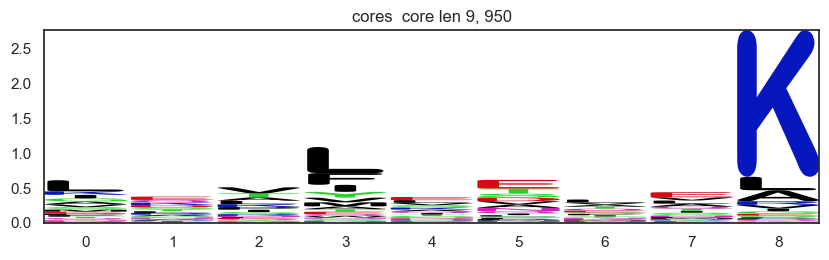

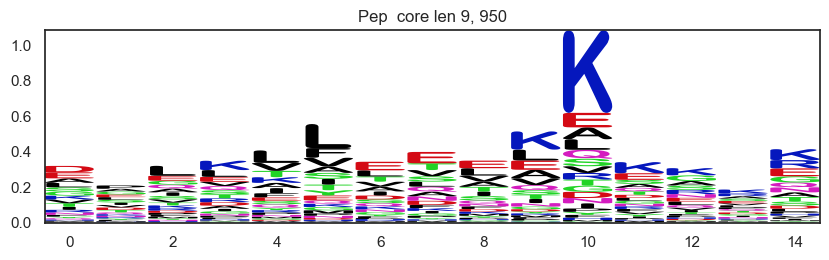

In [17]:
restricted_motif(target_df, core_len=9, use_peptides=True)

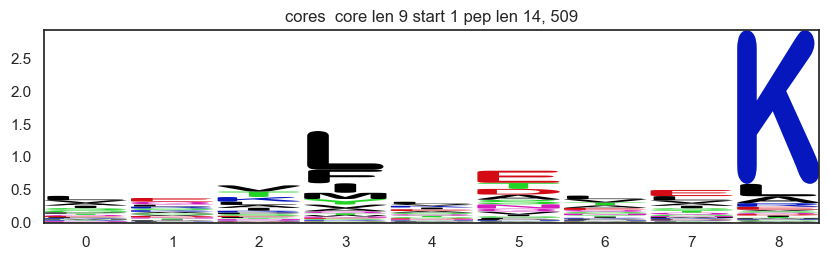

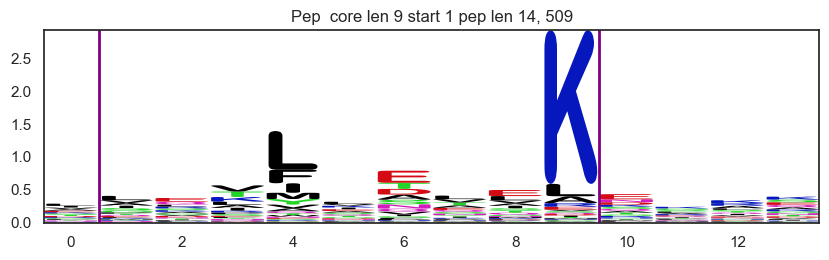

In [39]:
target_peptide_len = 14
target_core_len = 9
core_start = 1
df = restricted_motif(data_df,
                      peptide_len=target_peptide_len, core_len=target_core_len,
                      use_peptides=True,
                      core_start=core_start,mark_left=core_start, mark_right=core_start+target_core_len
                      )


In [19]:
left_parts = df.peptide.str.slice(0, core_start)
right_parts = df.peptide.str.slice(core_start + target_core_len)


In [20]:
right_parts

GFTVVHETEKHEKQQ    HEKQQ
RLSALLQETKELKNE    ELKNE
IVEVINENVKKSRRL    KSRRL
KILKKHDKILETSRG    ETSRG
HITTLQASFLTKKLN    TKKLN
                   ...  
YLATLETLTKHYGAE    HYGAE
TSHRWPITILSFREF    SFREF
TYRAIANYEKTSGSE    TSGSE
IEELFLDLCKRMIET    RMIET
AARVAEQLRAYLEGE    YLEGE
Name: peptide, Length: 240, dtype: object

In [21]:
matrix = logomaker.alignment_to_matrix(left_parts.values)
matrix_with_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: x[1] == 'P')])
matrix_without_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: 'P' not in x[0:core_start] )])

# matrix_without_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: x.contains('P'))])
# matrix = logomaker.alignment_to_matrix(right_parts.values)
# matrix_without_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: 'P' not in x and 'G' in x)])


IndexError: string index out of range

In [ ]:
sns.heatmap(matrix, annot=True, linewidth=.5)


<AxesSubplot: ylabel='pos'>

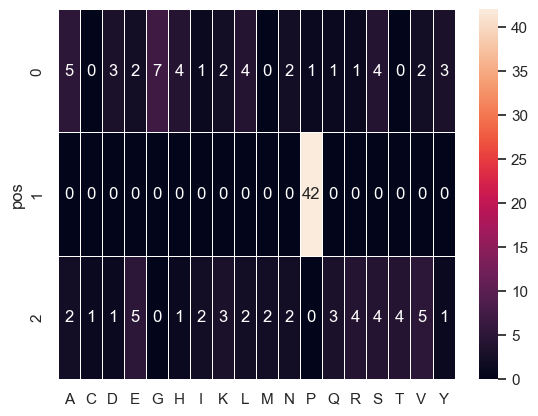

In [38]:
sns.heatmap(matrix_with_second_p, annot=True, linewidth=.5)

<AxesSubplot: ylabel='pos'>

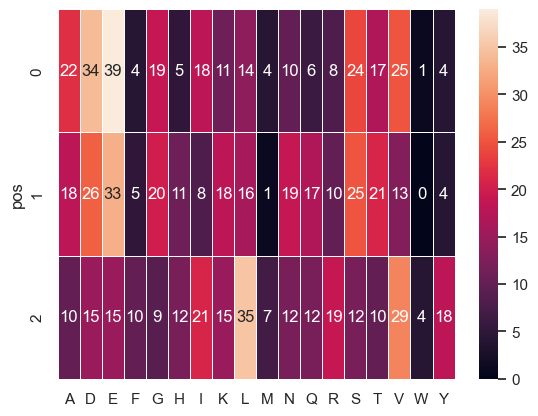

In [39]:
sns.heatmap(matrix_without_second_p, annot=True, linewidth=.5)


In [ ]:
left_parts[left_parts.apply(lambda x: 'P' not in x and 'G' in x)]

## Result if MIXMHCpred


In [18]:
df = pd.read_table('test_data/peptides_mixmhcpred.txt')
df

,Peptide,Context,BestAllele,%Rank_best,Core_best,CoreP1_best,SubSpec_best,%Rank_DPA1_02_01__DPB1_05_01,CoreP1_DPA1_02_01__DPB1_05_01,SubSpec_DPA1_02_01__DPB1_05_01
0,ETSAKEAINVEQAFQTI,NaN,DPA1_02_01__DPB1_05_01,2.070,KEAINVEQA,5,1,2.070,5,1
1,GPESSKKYAEAVTRAKQ,NaN,DPA1_02_01__DPB1_05_01,13.100,KYAEAVTRA,7,1,13.100,7,1
2,THLETFYNEEKDKKF,NaN,DPA1_02_01__DPB1_05_01,0.128,LETFYNEEK,3,-1,0.128,3,-1
3,TSILQTLCEQLRKENEAL,NaN,DPA1_02_01__DPB1_05_01,34.500,LQTLCEQLR,4,-1,34.500,4,-1
4,IPFRAADLLLHSKA,NaN,DPA1_02_01__DPB1_05_01,4.710,RAADLLLHS,4,1,4.710,4,1
...,...,...,...,...,...,...,...,...,...,...
5611,GILDVQSVQEKRKKKE,NaN,DPA1_02_01__DPB1_05_01,8.460,LDVQSVQEK,3,-1,8.460,3,-1
5612,SIIETMKDQQKREIK,NaN,DPA1_02_01__DPB1_05_01,0.699,IETMKDQQK,3,-1,0.699,3,-1
5613,EVLLLKSLGKERKHL,NaN,DPA1_02_01__DPB1_05_01,10.100,VLLLKSLGK,2,-1,10.100,2,-1
5614,LATLETLTKHYGA,NaN,DPA1_02_01__DPB1_05_01,3.390,LATLETLTK,1,-1,3.390,1,-1


In [19]:
df.CoreP1_best.value_counts()

4     1693
3     1475
2      953
5      865
1      339
6      204
7       56
8       17
9       10
10       4
Name: CoreP1_best, dtype: int64

In [20]:
motif_types = list(df.SubSpec_best.value_counts().keys())

NameError: name 'make_logo_for_data' is not defined

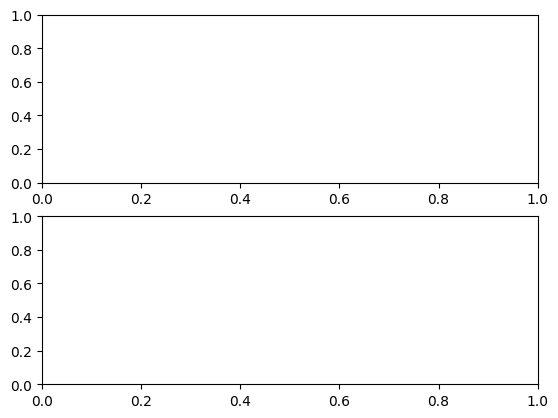

In [21]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(nrows=2)
for i, motif_type in enumerate(motif_types):
    data = df[df.SubSpec_best == motif_type].Core_best.to_numpy()
    make_logo_for_data(data, f"Motif group {motif_type}", ax=axes[i] )
plt.tight_layout()

In [22]:
df = df.rename(columns={"Peptide": "peptide", "CoreP1_best": "core_start", "Core_best":  "core_peptide"  })
df['peptide_len'] = df.peptide.str.len()
df['core_start']  = df['core_start'] - 1
df['core_len'] = df.core_peptide.str.len()
df['core_end'] = df['core_start'] + df['core_len']

df = df.set_index('peptide')
df['peptide'] = df.index.values

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


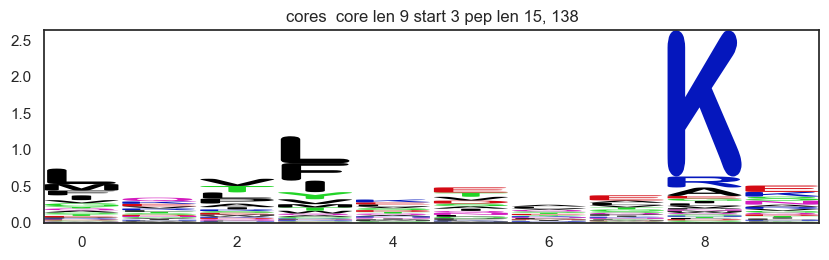

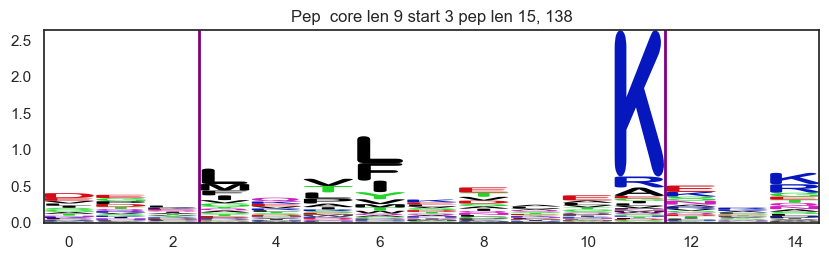

In [110]:
target_peptide_len = 15
target_core_len = 9
core_start = 3
res = restricted_motif(df[df.SubSpec_best == -1],
                      peptide_len=target_peptide_len, core_len=target_core_len,
                      use_peptides=True,
                      core_start=core_start,mark_left=core_start, mark_right=core_start+target_core_len
                      )

In [105]:
df.peptide_len.value_counts()

14    1240
15    1227
16     925
13     789
17     619
12     420
18     396
Name: peptide_len, dtype: int64

In [49]:
    peptides = df.index.values

In [50]:
peptides

array([   0,    1,    2, ..., 5613, 5614, 5615], dtype=int64)

In [73]:
df.core_start.value_counts()

6    17
Name: core_start, dtype: int64

In [17]:
data_df

,allele,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
ETSAKEAINVEQAFQTI,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 4.17 4.17 5.24 5.24 5.24 5.24 ...,ETSAKEAINVEQAFQTI,3,11,9,17,AKEAINVEQ,[4.17 4.17 5.24 5.24 5.24 5.24 5.24 5.24 5.24]
GPESSKKYAEAVTRAKQ,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 0. 4.2 5.22 5.22 5.22 5.22 ...,GPESSKKYAEAVTRAKQ,4,12,9,17,SKKYAEAVT,[4.2 5.22 5.22 5.22 5.22 5.22 5.22 5.22 5.22]
THLETFYNEEKDKKF,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 4.1 5.12 5.12 5.12 5.12 5.12 5.12 ...,THLETFYNEEKDKKF,2,10,9,15,LETFYNEEK,[4.1 5.12 5.12 5.12 5.12 5.12 5.12 5.12 5.12]
TSILQTLCEQLRKENEAL,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 4.13 5.17 5.17 5.17 5.17 5.17 ...,TSILQTLCEQLRKENEAL,3,11,9,18,LQTLCEQLR,[4.13 5.17 5.17 5.17 5.17 5.17 5.17 5.17 5.17]
IPFRAADLLLHSKA,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 2.12 2.12 5.25 5.25 5.25 5.25 5.25 ...,IPFRAADLLLHSKA,4,12,9,14,AADLLLHSK,[5.25 5.25 5.25 5.25 5.25 5.25 5.25 3.13 3.13]
...,...,...,...,...,...,...,...,...,...
GILDVQSVQEKRKKKE,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 4.12 5.14 5.14 5.14 5.14 5.14 5.14 ...,GILDVQSVQEKRKKKE,2,10,9,16,LDVQSVQEK,[4.12 5.14 5.14 5.14 5.14 5.14 5.14 5.14 5.14]
SIIETMKDQQKREIK,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 4.08 5.09 5.09 5.09 5.09 5.09 5.09 ...,SIIETMKDQQKREIK,2,10,9,15,IETMKDQQK,[4.08 5.09 5.09 5.09 5.09 5.09 5.09 5.09 5.09]
EVLLLKSLGKERKHL,HLA-DPA1*02:02/DPB1*05:01,[0. 4.12 5.13 5.13 5.13 5.13 5.13 5.13 5.13 ...,EVLLLKSLGKERKHL,1,9,9,15,VLLLKSLGK,[4.12 5.13 5.13 5.13 5.13 5.13 5.13 5.13 5.13]
LATLETLTKHYGA,HLA-DPA1*02:02/DPB1*05:01,[4.07 5.08 5.08 5.08 5.08 5.08 5.08 5.08 5.08 ...,LATLETLTKHYGA,0,8,9,13,LATLETLTK,[4.07 5.08 5.08 5.08 5.08 5.08 5.08 5.08 5.08]


In [35]:
subset_df = df[df.SubSpec_best == 1] 

In [50]:
peptide = subset_df.iloc[10].peptide

In [51]:
peptide

'SDYNIQKESTLHLVLR'

In [52]:
peptide in data_df.peptide

True

In [56]:
data_df.loc[subset_df.peptide]

,allele,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
ETSAKEAINVEQAFQTI,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 4.17 4.17 5.24 5.24 5.24 5.24 ...,ETSAKEAINVEQAFQTI,3,11,9,17,AKEAINVEQ,[4.17 4.17 5.24 5.24 5.24 5.24 5.24 5.24 5.24]
GPESSKKYAEAVTRAKQ,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 0. 4.2 5.22 5.22 5.22 5.22 ...,GPESSKKYAEAVTRAKQ,4,12,9,17,SKKYAEAVT,[4.2 5.22 5.22 5.22 5.22 5.22 5.22 5.22 5.22]
IPFRAADLLLHSKA,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 2.12 2.12 5.25 5.25 5.25 5.25 5.25 ...,IPFRAADLLLHSKA,4,12,9,14,AADLLLHSK,[5.25 5.25 5.25 5.25 5.25 5.25 5.25 3.13 3.13]
PFRAADLLLHSK,HLA-DPA1*02:02/DPB1*05:01,[0. 4.2 4.2 5.28 5.28 5.28 5.28 5.28 5.28 ...,PFRAADLLLHSK,1,9,9,12,FRAADLLLH,[4.2 4.2 5.28 5.28 5.28 5.28 5.28 5.28 5.28]
VVGKEPESILQVLSQ,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 1.07 1.07 2.13 5.29 5.29 5.29 5.29 ...,VVGKEPESILQVLSQ,5,13,9,15,PESILQVLS,[5.29 5.29 5.29 5.29 5.29 5.29 4.22 4.22 3.16]
...,...,...,...,...,...,...,...,...,...
IMEKTAEHFQEA,HLA-DPA1*02:02/DPB1*05:01,[0. 3.16 5.26 5.26 5.26 5.26 5.26 5.26 5.26 ...,IMEKTAEHFQEA,1,9,9,12,MEKTAEHFQ,[3.16 5.26 5.26 5.26 5.26 5.26 5.26 5.26 5.26]
YRLKEYEKALKYVRG,HLA-DPA1*02:02/DPB1*05:01,[1.06 1.06 5.12 5.12 5.12 5.12 5.12 5.12 5.12 ...,YRLKEYEKALKYVRG,2,10,9,15,LKEYEKALK,[5.12 5.12 5.12 5.12 5.12 5.12 5.12 4.06 4.06]
DLFQKILVPIQQVLKE,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 0. 0. 0. 4.16 5.21 5.21 ...,DLFQKILVPIQQVLKE,6,14,9,16,LVPIQQVLK,[4.16 5.21 5.21 5.21 5.21 5.21 5.21 5.21 5.21]
IKGKTHSQLLIIDR,HLA-DPA1*02:02/DPB1*05:01,[0. 1.1 4.27 5.36 5.36 5.36 5.36 5.36 5.36 ...,IKGKTHSQLLIIDR,2,10,9,14,GKTHSQLLI,[4.27 5.36 5.36 5.36 5.36 5.36 5.36 5.36 4.26]


In [54]:
subset_df.head(50)

,Context,BestAllele,%Rank_best,core_peptide,core_start,SubSpec_best,%Rank_DPA1_02_01__DPB1_05_01,CoreP1_DPA1_02_01__DPB1_05_01,SubSpec_DPA1_02_01__DPB1_05_01,peptide_len,core_len,core_end,peptide
peptide,,,,,,,,,,,,,
ETSAKEAINVEQAFQTI,NaN,DPA1_02_01__DPB1_05_01,2.0700,KEAINVEQA,4,1,2.0700,5,1,17,9,13,ETSAKEAINVEQAFQTI
GPESSKKYAEAVTRAKQ,NaN,DPA1_02_01__DPB1_05_01,13.1000,KYAEAVTRA,6,1,13.1000,7,1,17,9,15,GPESSKKYAEAVTRAKQ
IPFRAADLLLHSKA,NaN,DPA1_02_01__DPB1_05_01,4.7100,RAADLLLHS,3,1,4.7100,4,1,14,9,12,IPFRAADLLLHSKA
PFRAADLLLHSK,NaN,DPA1_02_01__DPB1_05_01,30.4000,RAADLLLHS,2,1,30.4000,3,1,12,9,11,PFRAADLLLHSK
VVGKEPESILQVLSQ,NaN,DPA1_02_01__DPB1_05_01,1.0100,KEPESILQV,3,1,1.0100,4,1,15,9,12,VVGKEPESILQVLSQ
TPGKEAVAMESYAKA,NaN,DPA1_02_01__DPB1_05_01,0.4100,KEAVAMESY,3,1,0.4100,4,1,15,9,12,TPGKEAVAMESYAKA
KTKNSEEFAAAM,NaN,DPA1_02_01__DPB1_05_01,0.1800,KNSEEFAAA,2,1,0.1800,3,1,12,9,11,KTKNSEEFAAAM
EEFKRYEMLKEHER,NaN,DPA1_02_01__DPB1_05_01,1.9400,KRYEMLKEH,3,1,1.9400,4,1,14,9,12,EEFKRYEMLKEHER
HPTKIPVIIERYKG,NaN,DPA1_02_01__DPB1_05_01,2.5100,KIPVIIERY,3,1,2.5100,4,1,14,9,12,HPTKIPVIIERYKG
